In [324]:
try:
    import h2o
except:
    !pip install -qq -U h2o
    import h2o

from h2o import H2OFrame
from h2o.automl import H2OAutoML

print("h2o version:", h2o.__version__)

h2o version: 3.46.0.12


In [325]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [326]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [327]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns
# import shap

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, label_binarize, TargetEncoder as skTE

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [328]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [329]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")

TARGET, ID = 'is_fraud', 'id'

## -- Check if id is unique --
if ID in train.columns:
    if train.id.is_unique:
        print(f"Train ID column is unique: {train.id.is_unique}... Dropped ✅!")
        train = train.drop(columns=[ID])
        test  = test.drop(columns=[ID])
        if ID in orig.columns:
            orig = orig.drop(columns=[ID])

Train ID column is unique: True... Dropped ✅!


In [330]:
# train[TARGET] = train[TARGET].map({True: 1, False: 0})
# orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
bol = train.select_dtypes(include=[bool]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET]]
bool_cols = [c for c in bol if c not in [TARGET]]
num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
base_cols = [c for c in train.columns if c not in [TARGET]]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name:5s} shape: {df.shape}")
    
print(f"\nDataFrame type: {type(train)}")
print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total Boolean: {len(bool_cols)}")
print(f"Total base features: {len(base_cols)}")

Train shape: (699960, 25)
Test  shape: (299984, 24)
Orig  shape: (20000, 25)

DataFrame type: <class 'pandas.core.frame.DataFrame'>
Total Numerical: 13
Total Categorical: 5
Total Boolean: 6
Total base features: 24


In [331]:
float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    # 'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

train.head()

,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [332]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

used_vpn                            2
is_fraud                            2
is_ai_generated_scam_attempt        2
billing_shipping_mismatch           2
is_foreign_transaction              2
ip_country_mismatch                 2
is_new_merchant                     2
cvv_retry_count                     4
channel                             5
prior_disputes                      5
auth_method                         5
card_type                           5
day_of_week                         7
device_type                         8
merchant_category                  12
txn_count_last_24h                 12
time_of_day_hour                   24
card_age_months                    49
customer_age                       64
velocity_score                    666
merchant_risk_score               950
hours_since_last_txn             3633
distance_from_home_km            4365
amount_usd                      13387
account_balance_usd             43317
dtype: int64

In [333]:
def get_class_weights(y):
    """
    y: Current y labels -> numpy array or series
    """
    cls_ = np.unique(y)
    wts_ = compute_class_weight("balanced", classes=cls_, y=y)
    return dict(zip(cls_, wts_))

def get_sample_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        return np.array([opt[label] for label in y])
    else:
        cls_ = np.unique(y_true)
        wts_ = compute_class_weight('balanced', classes=cls_, y=y_true)
        cls_wts = dict(zip(cls_, wts_))
        return np.array([cls_wts[label] for label in y])

def reduce_memory(df):
    old_size = sys.getsizeof(df) / (1024**2)
    for c in tqdm(df.columns, desc='Reducing memory...'):
        if df[c].dtype == np.int64:
            ## -- Downcast Integer type ---
            if df[c].min() > np.iinfo(np.int32).min and df[c].max() < np.iinfo(np.int32).max:
                df[c] = df[c].astype(np.int32)
                # if df[c].min() > np.iinfo(np.int16).min and df[c].max() < np.iinfo(np.int16).max:
                #     df[c] = df[c].astype(np.int16)
                #     if df[c].min() > np.iinfo(np.int8).min and df[c].max() < np.iinfo(np.int8).max:
                #         df[c] = df[c].astype(np.int8)
        elif df[c].dtype == np.float64:
            ## -- Downcast Float type -----
            if df[c].min() > np.finfo(np.float32).min and df[c].max() < np.finfo(np.float32).max:
                df[c] = df[c].astype(np.float32)
                # if df[c].min() > np.finfo(np.float16).min and df[c].max() < np.finfo(np.float16).max:
                #     df[c] = df[c].astype(np.float16)

    new_size = sys.getsizeof(df) / (1024**2)
    print(f"Size before process: {old_size:.1f}MB\nSize after process : {new_size:.1f}MB\n")

    return df

print('- Helper functions ready -')

- Helper functions ready -


## FEATURE ENGINEERING

In [334]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique', 
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the 
        global mean. If 'auto', an empirical Bayes estimate is used.
        
    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping
        
        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f"TE_{col}_{agg_func}"
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)
        
        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)
            
        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)
        
        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]
            
            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'
                    
                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)
                    
                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()
                        
                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups
                        
                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)
                    
                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]
            
        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)
            
        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [335]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [336]:
FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

combined = pd.concat([train, test, orig], ignore_index=True)
digit_cols = []

for col in num_cols:
    scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
    for k in range(-2, 3):
        dig_col = f"{col}_DIGIT_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 37



velocity_score_DIGIT_-1           10
merchant_risk_score_DIGIT_-1      10
account_balance_usd_DIGIT_-1      10
amount_usd_DIGIT_-2               10
day_of_week_DIGIT_0                7
card_age_months_DIGIT_0           10
distance_from_home_km_DIGIT_-2    10
customer_age_DIGIT_1               8
distance_from_home_km_DIGIT_-1    10
hours_since_last_txn_DIGIT_1       6
distance_from_home_km_DIGIT_0     10
txn_count_last_24h_DIGIT_0        10
cvv_retry_count_DIGIT_0            4
time_of_day_hour_DIGIT_0          10
prior_disputes_DIGIT_0             5
hours_since_last_txn_DIGIT_0      10
account_balance_usd_DIGIT_-2      10
account_balance_usd_DIGIT_1       10
merchant_risk_score_DIGIT_1       10
card_age_months_DIGIT_1            6
velocity_score_DIGIT_0            10
merchant_risk_score_DIGIT_2        2
velocity_score_DIGIT_1             8
amount_usd_DIGIT_-1               10
amount_usd_DIGIT_2                10
hours_since_last_txn_DIGIT_-1     10
amount_usd_DIGIT_0                10
d

In [337]:
def digit_keys(df1, cols=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

train, digit_cols2 = digit_keys(train)
test, _ = digit_keys(test)

print(train.shape, test.shape)
train[digit_cols2].nunique()

(699960, 98) (299984, 97)


amount_usd__int                   1144
amount_usd__int10                  235
amount_usd__tenths                4599
amount_usd__cents                  100
amount_usd__lead1                   33
amount_usd__lead2                  217
account_balance_usd__int          4928
account_balance_usd__int10        1116
account_balance_usd__tenths      19083
account_balance_usd__cents         100
account_balance_usd__lead1          28
account_balance_usd__lead2         196
hours_since_last_txn__int           51
hours_since_last_txn__int10          6
hours_since_last_txn__tenths       502
hours_since_last_txn__cents        100
hours_since_last_txn__lead1         15
hours_since_last_txn__lead2         51
distance_from_home_km__int          56
distance_from_home_km__int10         6
distance_from_home_km__tenths      542
distance_from_home_km__cents       100
distance_from_home_km__lead1        15
distance_from_home_km__lead2        56
velocity_score__int                 73
velocity_score__int10    

In [338]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig], ignore_index=True)
## ------------------------------------------------------------

# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols

for c in tqdm(select_nc, desc="nums_to_cats"):
    n_cat = f"{c}_CAT_"
    combined[n_cat], _ = pd.factorize(combined[c], sort=True)
    combined[n_cat] = combined[n_cat].astype('category')
    nums_to_cats.append(n_cat)

FEATURES = list(set(FEATURES + nums_to_cats))
## ------------------------------------------------------------

train = combined.iloc[:train_len] #[FEATURES+[TARGET]]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 97


nums_to_cats:   0%|          | 0/13 [00:00<?, ?it/s]

Total features after operation: 110


In [339]:
# ## -- Factorize cat_cols -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
# print("Total features before operation:", len(FEATURES))

# combined = pd.concat([train, test, orig])
# ## ------------------------------------------------------------------------

# for c in tqdm(cat_cols, desc="factorize_cats"):
#     combined[c] = pd.factorize(combined[c], sort=True)[0].astype('int32')
# ## ------------------------------------------------------------------------

# GROUPERS = []
# for col in service_cols:
#     g_col = f"{col}_FD_GROUPBY".replace(" ", "")
#     combined[g_col+'mean'] = combined.groupby(['Flight Distance'])[col].transform('mean')
#     GROUPERS.append(g_col)
# FEATURES = list(set(FEATURES + GROUPERS))
# ## ------------------------------------------------------------------------

# for c in tqdm(cat_cols, desc="categorize_cats"):
#     combined[c] = combined[c].astype("category")
# ## ------------------------------------------------------------------------
# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Total features after operation:", len(FEATURES))

In [340]:
# ## -- INTERACTIONS -- ⚠️

# INTER = []

# combined = pd.concat([train, test, orig], ignore_index=True)
# # ------------------------------------------------------------------------
# # combo_2_1 = list(itertools.combinations(cat_cols, 2))
# # for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
# #     n_col = f"Bi_{c1}_X_{c2}"
# #     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
# #     combined[n_col.strip()] = pd.factorize(combo_string, sort=True)[0].astype('int32')
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)  

# combo_3_1 = list(itertools.combinations(cat_cols, 3)) # +[age_n]
# for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
#     n_col = f"Tri_{c1}_X_{c2}_X_{c3}"
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
#     combined[n_col] = pd.factorize(combo_string, sort=True)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

# # combo_1_to_many = list(itertools.product(cat_cols, ["Age"]))
# # for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
# #     n_col = f"Bi2_{c1}_X_{c2}"
# #     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
# #     combined[n_col.strip()] = pd.factorize(combo_string, sort=True)[0].astype('int32')
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)
# # ------------------------------------------------------------------------
# for n_col in INTER:
#     train[n_col] = combined[n_col].iloc[:train_len].values
#     test[n_col]  = combined[n_col].iloc[train_len:train_len + test_len].values
#     orig[n_col]  = combined[n_col].iloc[train_len + test_len:].values

# print(f"Total Interaction Features: {INTER}")

# del combined
# # train[INTER].head()

In [341]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=90_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

print(f"Train shape {train_X.shape}")
train_X.head()

(699960, 111) <class 'pandas.core.frame.DataFrame'>
Total Features: 110
Train shape (699960, 111)


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,amount_usd_DIGIT_-2,amount_usd_DIGIT_-1,amount_usd_DIGIT_0,amount_usd_DIGIT_1,amount_usd_DIGIT_2,hours_since_last_txn_DIGIT_-2,hours_since_last_txn_DIGIT_-1,hours_since_last_txn_DIGIT_0,hours_since_last_txn_DIGIT_1,txn_count_last_24h_DIGIT_0,txn_count_last_24h_DIGIT_1,distance_from_home_km_DIGIT_-2,distance_from_home_km_DIGIT_-1,distance_from_home_km_DIGIT_0,distance_from_home_km_DIGIT_1,card_age_months_DIGIT_0,card_age_months_DIGIT_1,customer_age_DIGIT_0,customer_age_DIGIT_1,account_balance_usd_DIGIT_-2,account_balance_usd_DIGIT_-1,account_balance_usd_DIGIT_0,account_balance_usd_DIGIT_1,account_balance_usd_DIGIT_2,cvv_retry_count_DIGIT_0,...,prior_disputes_DIGIT_0,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0,6,1,1,6,0,7,7,9,0,1,0,8,7,7,1,8,4,6,5,5,3,9,6,2,0,...,0,61.0,6.0,611.0,16.0,26.0,261.0,1269.0,126.0,12693.0,35.0,41.0,412.0,9.0,0.0,97.0,77.0,19.0,109.0,17.0,1.0,177.0,78.0,21.0,217.0,5.0,0.0,55.0,50.0,15.0,105.0,29.0,2.0,292.0,20.0,22.0,229.0,5318,976,1,1775,25,38,21485,0,55,17,3,293,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0,3,8,4,2,0,4,5,1,0,3,0,6,0,3,1,8,3,8,2,0,0,3,3,2,0,...,1,24.0,2.0,248.0,83.0,22.0,224.0,3233.0,323.0,32330.0,0.0,43.0,432.0,1.0,0.0,15.0,54.0,11.0,101.0,13.0,1.0,130.0,6.0,21.0,213.0,33.0,3.0,334.0,40.0,23.0,233.0,29.0,2.0,299.0,90.0,22.0,229.0,2179,153,3,1304,15,10,43629,0,335,23,5,300,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0,6,3,6,0,0,0,2,1,0,4,0,7,1,8,0,0,5,5,5,8,8,6,4,0,0,...,0,6.0,0.0,63.0,36.0,16.0,106.0,1046.0,104.0,10468.0,88.0,41.0,410.0,1.0,0.0,12.0,20.0,11.0,101.0,8.0,0.0,81.0,17.0,18.0,108.0,35.0,3.0,358.0,80.0,23.0,235.0,24.0,2.0,241.0,10.0,22.0,224.0,430,119,4,817,27,37,16650,0,359,15,0,242,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0,4,4,7,3,0,3,1,5,0,4,0,7,6,8,0,8,4,8,4,7,6,7,1,2,0,...,0,37.0,3.0,374.0,44.0,23.0,237.0,2217.0,221.0,22176.0,67.0,42.0,422.0,5.0,0.0,51.0,13.0,15.0,105.0,8.0,0.0,86.0,67.0,18.0,108.0,20.0,2.0,207.0,70.0,22.0,220.0,41.0,4.0,419.0,90.0,24.0,241.0,3322,512,4,867,25,30,34746,0,207,7,3,420,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0

In [342]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = False

import_cols  = [] # 

if USE_ORIGINAL:
    aggs_ = ["mean", "count"]  # "mean", "count", "std", "skew", "nunique", 
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype(np.int8)
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype(np.int8)

print(X.shape, type(X))
X.head()

(699960, 110) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_DIGIT_-2,amount_usd_DIGIT_-1,amount_usd_DIGIT_0,amount_usd_DIGIT_1,amount_usd_DIGIT_2,hours_since_last_txn_DIGIT_-2,hours_since_last_txn_DIGIT_-1,hours_since_last_txn_DIGIT_0,hours_since_last_txn_DIGIT_1,txn_count_last_24h_DIGIT_0,txn_count_last_24h_DIGIT_1,distance_from_home_km_DIGIT_-2,distance_from_home_km_DIGIT_-1,distance_from_home_km_DIGIT_0,distance_from_home_km_DIGIT_1,card_age_months_DIGIT_0,card_age_months_DIGIT_1,customer_age_DIGIT_0,customer_age_DIGIT_1,account_balance_usd_DIGIT_-2,account_balance_usd_DIGIT_-1,account_balance_usd_DIGIT_0,account_balance_usd_DIGIT_1,account_balance_usd_DIGIT_2,cvv_retry_count_DIGIT_0,velocity_score_DIGIT_-1,...,prior_disputes_DIGIT_0,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,amount_usd_CAT_,hours_since_last_txn_CAT_,txn_count_last_24h_CAT_,distance_from_home_km_CAT_,card_age_months_CAT_,customer_age_CAT_,account_balance_usd_CAT_,cvv_retry_count_CAT_,velocity_score_CAT_,time_of_day_hour_CAT_,day_of_week_CAT_,merchant_risk_score_CAT_,prior_disputes_CAT_
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,6,1,1,6,0,7,7,9,0,1,0,8,7,7,1,8,4,6,5,5,3,9,6,2,0,5,...,0,61.0,6.0,611.0,16.0,26.0,261.0,1269.0,126.0,12693.0,35.0,41.0,412.0,9.0,0.0,97.0,77.0,19.0,109.0,17.0,1.0,177.0,78.0,21.0,217.0,5.0,0.0,55.0,50.0,15.0,105.0,29.0,2.0,292.0,20.0,22.0,229.0,5318,976,1,1775,25,38,21485,0,55,17,3,293,0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,3,8,4,2,0,4,5,1,0,3,0,6,0,3,1,8,3,8,2,0,0,3,3,2,0,4,...,1,24.0,2.0,248.0,83.0,22.0,224.0,3233.0,323.0,32330.0,0.0,43.0,432.0,1.0,0.0,15.0,54.0,11.0,101.0,13.0,1.0,130.0,6.0,21.0,213.0,33.0,3.0,334.0,40.0,23.0,233.0,29.0,2.0,299.0,90.0,22.0,229.0,2179,153,3,1304,15,10,43629,0,335,23,5,300,1
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,6,3,6,0,0,0,2,1,0,4,0,7,1,8,0,0,5,5,5,8,8,6,4,0,0,8,...,0,6.0,0.0,63.0,36.0,16.0,106.0,1046.0,104.0,10468.0,88.0,41.0,410.0,1.0,0.0,12.0,20.0,11.0,101.0,8.0,0.0,81.0,17.0,18.0,108.0,35.0,3.0,358.0,80.0,23.0,235.0,24.0,2.0,241.0,10.0,22.0,224.0,430,119,4,817,27,37,16650,0,359,15,0,242,0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,4,4,7,3,0,3,1,5,0,4,0,7,6,8,0,8,4,8,4,7,6,7,1,2,0,7,...,0,37.0,3.0,374.0,44.0,23.0,237.0,2217.0,221.0,22176.0,67.0,42.0,422.0,5.0,0.0,51.0,13.0,15.0,105.0,8.0,0.0,86.0,67.0,18.0,108.0,20.0,2.0,207.0,70.0,22.0,220.0,41.0,4.0,419.0,90.0,24.0,241.0,3322,512,4,867,25,30,34746,0,207,7,3,420,0
4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4

## Config | Trainer

In [343]:
# ## -- Trainer for h2o.H20Frame
# def Trainer_CV(model_name, params, train_df, test_df, features, target, kf, cat_cols):
#     print(f"\n===== Starting CV: {model_name} =====")
#     start = time()

#     y = train_df[target]
#     num_cls = y.nunique()

#     oof_preds = np.zeros((len(train_df), num_cls))
#     test_preds = np.zeros((len(test_df), num_cls))
#     fold_scores = []

#     oof_glm = np.zeros((len(train_df), num_cls))
#     oof_gbm = np.zeros((len(train_df), num_cls))
#     oof_drf = np.zeros((len(train_df), num_cls))
#     oof_xgb = np.zeros((len(train_df), num_cls))
#     oof_dpl = np.zeros((len(train_df), num_cls))

#     test_glm = np.zeros((len(test_df), num_cls))
#     test_gbm = np.zeros((len(test_df), num_cls))
#     test_drf = np.zeros((len(test_df), num_cls))
#     test_xgb = np.zeros((len(test_df), num_cls))
#     test_dpl = np.zeros((len(test_df), num_cls))

#     h2o_models = [
#         ("glm", oof_glm, test_glm),
#         ("gbm", oof_gbm, test_gbm),
#         ("drf", oof_drf, test_drf),
#         ("xgboost", oof_xgb, test_xgb),
#         ("deeplearning", oof_dpl, test_dpl),
#     ]
#     ## ---------------------------------------------------------------------------------
#     h2o.init(verbose=True, nthreads=os.cpu_count(), max_mem_size="20G")
    
#     test_df[TARGET] = "Null"
#     df_ = pd.concat([train_df, test_df])
#     h2o_df = H2OFrame(df_)

#     ## -- Split train set --
#     h2o_train = h2o_df[h2o_df[TARGET] != "Null"]
#     h2o_train[TARGET] = h2o_train[TARGET].asfactor()

#     ## -- Split test set --
#     h2o_test = h2o_df[h2o_df[TARGET] == "Null"]
#     # h2o_test = h2o_test.drop([TARGET])

#     for col in cat_cols:
#         h2o_train[col] = h2o_train[col].asfactor()
#         h2o_test[col]  = h2o_test[col].asfactor()
#     ## ---------------------------------------------------------------------------------

#     n_splits = kf.n_splits

#     for idx, (train_idx, val_idx) in enumerate(kf.split(train_df[features], y)):
#         print(f"\n{CFG["YELLOW"]}##### FOLD {idx+1}/{n_splits} | ", end="")

#         train_idx = list(train_idx.ravel())
#         val_idx = list(val_idx.ravel())

#         X_train = h2o_train[[int(i) for i in train_idx], :]
#         X_valid = h2o_train[[int(i) for i in val_idx], :]
#         X_test  = h2o_test[:, features]

#         print(f"Train shape: {X_train.shape}{CFG["RESET"]}")

#         ## --------------------------------------------------------------------------------------
#         model = H2OAutoML(**params)
#         model.train(features, target, training_frame=X_train, validation_frame=X_valid)
#         ## --------------------------------------------------------------------------------------
#         ## -- LEADER MODEL -- 
#         oof_preds_ = model.leader.predict(X_valid).as_data_frame(use_multi_thread=True)
#         oof_preds[val_idx] = oof_preds_.iloc[:, -num_cls:].to_numpy()

#         test_preds_ = model.leader.predict(X_test).as_data_frame(use_multi_thread=True)
#         test_preds += test_preds_.iloc[:, -num_cls:].to_numpy()
#         ## --------------------------------------------------------------------------------------
#         ## -- PER MODEL BASELINE -- 
#         for (mod, x_oof, x_tst) in h2o_models:
#             print(f" ••• Predicting with {mod}")
#             algo_model = model.get_best_model(algorithm=mod)

#             if algo_model is not None:
#                 single_oof = algo_model.predict(X_valid).as_data_frame(use_multi_thread=True)
#                 x_oof[val_idx] = single_oof.iloc[:, -num_cls:].to_numpy()

#                 single_test = algo_model.predict(X_test).as_data_frame(use_multi_thread=True)
#                 x_tst += single_test.iloc[:, -num_cls:].to_numpy()
#             else:
#                 print(f"    ⚠️ Warning: No model found for {mod} in this fold.")
#         ## ---------------------------------------------------------------------------------------

#         ## -- Get fold score --
#         # Use target mapping cleanly onto validation series
#         fold_score = balanced_acc(y[val_idx].map(mapping), oof_preds[val_idx])
#         fold_scores.append(fold_score)
#         print(f"{CFG["YELLOW"]} • Fold_{idx+1} bal_acc: {fold_score:.5f}{CFG["RESET"]}")

#     ## -- Average the test predictions outside the main fold loop
#     test_preds /= n_splits

#     ## -- FIX 3: Fixed variable unpacking for clean output messages
#     for (mod, __, x_tst) in tqdm(h2o_models, desc="Averaging model tests"):
#         print(f"• {mod}... ", end="")
#         x_tst /= n_splits

#     ## -- Print CV results
#     print("\n==================================================")
#     print(f"{n_splits}-FOLDS CV: {model_name}")
#     print("==================================================")
#     for i, score in enumerate(fold_scores):
#         print(f" • Fold {i+1} score: {score:.5f}")
    
#     ## -- Final out-of-fold --
#     overall_score = np.round(balanced_acc(y.map(mapping), oof_preds), 5)
#     print("-------------------------------------------------|")
#     print(f"OOF score: {overall_score}")
#     print(f"AVG score: {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")
#     print("-------------------------------------------------|")
#     print(f'{((time() - start) / 60):.2f} mins')

#     return {
#         "oof_preds": oof_preds,
#         "test_preds": test_preds,
#         "h2o": h2o_models,
#         "score": overall_score,
#         "model": model,
#         "val_data": X_valid, 
#     }

# print("⚙️ Trainer function ready ⚙️")

In [344]:
## -- Trainer for pandas DataFrame
def Trainer_CV(
    model_name, params, X, y, X_test, features, target, kfold,
    cat_cols=None, use_orig=False,
    use_weights=False, use_stack=False,
):
    print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
    t0 = time()

    ## - Initialize H2O once -- 
    h2o.init(verbose=False, max_mem_size="20G") 

    # X = train_df[features]
    # y = train_df[target].astype(str)

    N_SPLITS = kfold.n_splits

    oof_preds   = np.zeros(len(X))
    test_preds  = np.zeros(len(X_test))
    fold_scores = []
    
    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print()
        print("="*15)
        print(f"### FOLD {idx}/{N_SPLITS}")
        print("="*15)

        X_train, X_valid = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
        y_train, y_valid = y.iloc[train_idx], y.iloc[val_idx]
        X_tst = X_test.copy()

        # ## -- OPTION: Concatenate original data --
        # X_train = pd.concat([X_train, orig[features]], ignore_index=True)
        # y_train = pd.concat([y_train, orig[target]], ignore_index=True)

        if use_weights:
            print("Using weights ✓")
            def h2o_flat_weights(y):
                class_ratios = y.value_counts(normalize=True).sort_index().values
                print(f"Class_ratios: {class_ratios}")
                proportions = (1 / y.nunique()) / class_ratios
                print(f"Proportions: {proportions}")
                flat_weights = (proportions / min(proportions)).tolist()
                print(f"Flat weights: {flat_weights}")
                return flat_weights

            params['balance_classes'] = True
            params['class_sampling_factors'] = h2o_flat_weights(y_train)

        # Target encoding
        if 'nums_to_cats' in globals():
            te_cols = nums_to_cats + digit_cols2
            # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
            smooth = 'auto'
            print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
            TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
            tr_enc = TE.fit_transform(X_train[te_cols], y_train)
            va_enc = TE.transform(X_valid[te_cols])
            ts_enc = TE.transform(X_tst[te_cols])
    
            te_names = [f"TE{smooth}_{col}" for col in te_cols]
            X_train[te_names] = tr_enc
            X_valid[te_names] = va_enc
            X_tst[te_names] = ts_enc

            combos_to_drop = te_cols

            X_train = X_train.drop(columns=combos_to_drop)
            X_valid = X_valid.drop(columns=combos_to_drop)
            X_tst = X_tst.drop(columns=combos_to_drop)

        te_features = [c for c in X_train.columns if c.startswith('TE_')]

        print(f"train = {X_train.shape}, valid = {X_valid.shape}")

        # Prepare frames
        h2o_X_frame = H2OFrame(pd.concat([X_train, y_train], axis=1))
        h2o_V_frame = H2OFrame(pd.concat([X_valid, y_valid], axis=1))
        h2o_valid   = H2OFrame(X_valid)
        h2o_test    = H2OFrame(X_tst)

        # Recognize target as a factor column
        h2o_X_frame[target] = h2o_X_frame[target].asfactor()
        h2o_V_frame[target] = h2o_V_frame[target].asfactor()

        all_cat_cols = cat_cols
        for col in all_cat_cols:
            h2o_X_frame[col] = h2o_X_frame[col].asfactor()
            h2o_V_frame[col] = h2o_V_frame[col].asfactor()
            h2o_valid[col]   = h2o_valid[col].asfactor()
            h2o_test[col]    = h2o_test[col].asfactor()

        print(f"⚙️ H2O_Frame shape: {h2o_X_frame.shape}\n")
        # -------------------------------------------------------------------------------------
        
        model = H2OAutoML(**params)
        model.train(
            y = target,
            training_frame = h2o_X_frame,
            validation_frame = None if use_stack else h2o_V_frame,
        )
        # --------------------------------------------------------------------------------------
        # Leader Model -- 
        oof_predictions = model.leader.predict(h2o_valid).as_data_frame(use_multi_thread=True)
        oof_preds[val_idx] = oof_predictions.iloc[:, -1].to_numpy()

        test_predictions = model.leader.predict(h2o_test)
        display(test_predictions[:5, :])
        test_preds += test_predictions.as_data_frame(use_multi_thread=True).iloc[:, -1].to_numpy()
        # --------------------------------------------------------------------------------------

        fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
        fold_scores.append(fold_score)

        print(f"{CFG['YELLOW']}# FOLD {idx} AUC: {fold_score:.5f}{CFG['RESET']}")
        
    ## -------------------------------------------------------------------------
    # ## -- Fixed variable unpacking for clean output messages
    # for (mod, __, x_tst) in tqdm(h2o_models, desc="Averaging model tests"):
    #     print(f"• {mod}... ", end="")
    #     x_tst /= N_SPLITS

    ## -- Average test predictions
    test_preds /= N_SPLITS
    ## -------------------------------------------------------------------------

    ## -- CV results --
    print("\n==================================================")
    print(f"{N_SPLITS}-FOLD CV: {model_name} | {h2o_X_frame.shape}")
    print("==================================================")
    for i, s in enumerate(fold_scores, 1):
        print(f" • Fold {i} AUC: {s:.5f}")

    ## -- Final out-of-fold score --
    oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
    avg_auc = np.round(np.mean(fold_scores), 5)
    std_auc = np.round(np.std(fold_scores), 5)

    print("-------------------------------------------------|")
    print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
    print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
    print("-------------------------------------------------|")
    t1 = time()
    tt = (t1-t0)/60
    print(f"{tt:.2f} mins")

    return {
        "oof_preds": oof_preds,
        "test_preds": test_preds,
        "score": avg_auc,
        "model": model,
        "val_data": h2o_V_frame, 
        "name": model_name+f"({h2o_V_frame.shape[1]})",
    }

print("⚙️ Training function ready ⚙️")

⚙️ Training function ready ⚙️


In [345]:
FEATURES = [c for c in X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

FOLDS = 3
skf = StratifiedKFold(n_splits=FOLDS , shuffle=True, random_state=42)

for idx, (t_idx, v_idx) in enumerate(skf.split(X, y)):
    print(f"FOLD {idx+1}/{skf.n_splits} {'-'*25}")
    print(f"  train: {[int(i) for i in t_idx][25:30]}")
    print(f"  valid: {[int(i) for i in v_idx][25:30]}")

Total Features: 110
FOLD 1/3 -------------------------
  train: [38, 39, 40, 41, 42]
  valid: [86, 87, 91, 94, 98]
FOLD 2/3 -------------------------
  train: [35, 36, 37, 38, 40]
  valid: [77, 78, 82, 84, 88]
FOLD 3/3 -------------------------
  train: [44, 45, 47, 49, 50]
  valid: [61, 63, 65, 68, 69]


In [346]:
# !rm -r /kaggle/working/ 

In [355]:
# all_predictions = {}

KAGGLE_TIME = 42000
params = {
    'max_models': 20,
    'max_runtime_secs': (60*15)//FOLDS, #KAGGLE_TIME//FOLDS, #60*5, # 8000
    # 'max_runtime_secs_per_model': 300,
    # 'nfolds': 4, # 0 if validation_frame is provided, def=-1
    'stopping_rounds': 3,
    'stopping_metric': "AUC",
    # "preprocessing": ['target_encoding'],
    'seed': 42,
}

N_FEATS = len(FEATURES)

for VALUE in [True]:
    n = f"h2o_STACK({N_FEATS})_" if VALUE else f"h2o_BEST({N_FEATS})_"
    h_params["nfolds"] = 3 if VALUE else 0
    all_predictions[n] = Trainer_CV(
        model_name=n,
        params=params,
        X=X,
        y=y,
        X_test=X_test,
        features=FEATURES,
        target=TARGET,
        kfold=skf,
        cat_cols = cat_cols + bool_cols + digit_cols,
        use_stack=VALUE, 
        # use_orig=True,
        # use_weights=True,
    )


===== Starting CV: h2o_STACK(110)_ | GPU: Tesla T4 =====

### FOLD 1/3
⚡️ scikit_TE (smooth=auto) | features (49)
train = (466640, 110), valid = (233320, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (466640, 111)

AutoML progress: |
17:04:15.320: _train param, Dropping bad and constant columns: [merchant_risk_score_DIGIT_-2]

████
17:04:32.595: _train param, Dropping bad and constant columns: [merchant_risk_score_DIGIT_-2]

█████████████████████
17:06:13.455: _train param, Dropping bad and constant columns: [merchant_risk_score_DIGIT_-2]

███████████████████
17:07:46.478: _train param, Dropping bad and constant columns: [merchant_r

predict,p0,p1
0,0.999777,0.000222655
0,0.999869,0.000131066
0,0.937104,0.0628961
0,0.998709,0.00129103
0,0.999404,0.000595924


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 1 AUC: 0.94752

### FOLD 2/3
⚡️ scikit_TE (smooth=auto) | features (49)
train = (466640, 110), valid = (233320, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (466640, 111)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████

predict,p0,p1
0,0.99986,0.000140412
0,0.999925,7.45787e-05
0,0.941566,0.0584339
0,0.999358,0.000642235
0,0.999459,0.00054072


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 2 AUC: 0.95046

### FOLD 3/3
⚡️ scikit_TE (smooth=auto) | features (49)
train = (466640, 110), valid = (233320, 110)
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (466640, 111)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████

predict,p0,p1
0,0.999789,0.000211397
0,0.999893,0.000106612
0,0.931507,0.0684928
0,0.999012,0.000988183
0,0.999201,0.000798581


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
# FOLD 3 AUC: 0.94464

3-FOLD CV: h2o_STACK(110)_ | (466640, 111)
 • Fold 1 AUC: 0.94752
 • Fold 2 AUC: 0.95046
 • Fold 3 AUC: 0.94464
-------------------------------------------------|
OOF score: 0.94756
AVG score: 0.94754 ± 0.00238
-------------------------------------------------|
23.51 mins


In [356]:
# ==================================================
# 3-FOLD CV: h2o_STACK(110)_ | (466640, 111)
# ==================================================
#  • Fold 1 AUC: 0.94752
#  • Fold 2 AUC: 0.95046
#  • Fold 3 AUC: 0.94464
# -------------------------------------------------|
# OOF score: 0.94756
# AVG score: 0.94754 ± 0.00238
# -------------------------------------------------|
# 23.51 mins

# ==================================================
# 3-FOLD CV: h2o_BEST_(110)_ | (466640, 111)
# ==================================================
#  • Fold 1 AUC: 0.94752
#  • Fold 2 AUC: 0.95064
#  • Fold 3 AUC: 0.94507
# -------------------------------------------------|
# OOF score: 0.94775
# AVG score: 0.94774 ± 0.00228
# -------------------------------------------------|
# 24.20 mins

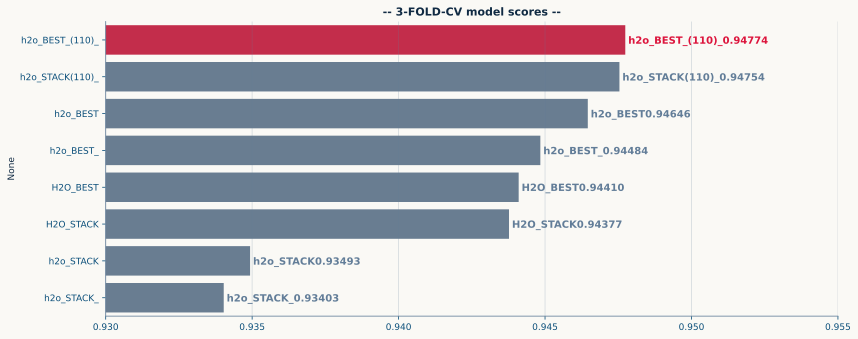

In [357]:
all_scores = {k: v.get("score") for k, v in all_predictions.items() if "score" in v}
results_df = pd.Series(all_scores).sort_values(ascending=False) #[:10]

all_names = {k: v.get("name") for k, v in all_predictions.items() if "name" in v}
# results_df = pd.Series(all_scores, index=all_names).sort_values(ascending=False) #[:10]

## -- Results --
max_val = results_df.max()
palette = [CRIM if c == max_val else MUTED for c in results_df.values]

plt.figure(figsize=(12, len(results_df)*0.6))

ax1 = sns.barplot(
    x=results_df.values,
    y=results_df.index,
    palette=palette,
    hue=results_df.index,
    orient="h",
    legend=False,
)

for i, s1 in enumerate(results_df.values):
    ax1.text(
        s1+1e-4,
        float(i),
        f"{results_df.index[i]}{s1:.5f}" if s1 == max_val else f"{results_df.index[i]}{s1:.5f}",
        ha="left",
        va='center_baseline',
        size=10,
        weight="semibold",
        color=CRIM if s1 == max_val else MUTED,
    )

plt.xlim((0.93, 0.955))
plt.title(f"-- {FOLDS}-FOLD-CV model scores --")

plt.tight_layout()
plt.show()

In [ ]:
## -- Get oof predictions --
oof_predictions = []

for i, (k, v) in enumerate(all_predictions.items()):
    for key_, data_ in v.items():
        if key_ == "oof_preds":
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"oof_{n}.npy", data_)
            print(f"{n} saved!")

            ## -- Plot distributions --
            _, axs = plt.subplots(1, 3, figsize=(12, 3.5)) 
            CalibrationDisplay.from_predictions(train_X[TARGET], data_, n_bins=10, name=n, ax=axs[0])
            axs[0].set_title("Calibration")

            RocCurveDisplay.from_predictions(train_X[TARGET], data_, name=n, ax=axs[1])
            axs[1].set_title("ROC-Curve")

            sns.histplot(data_, ax=axs[2], bins=50)
            axs[2].set_title("Distribution")
            
            plt.tight_layout()
            plt.show()

            print()

In [363]:
## -- Save test predictions/submissions --
model_results = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for j, (x, y) in enumerate(v.items()):
        if x == "test_preds":
            ## -- Base submission file --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"test_{n}.npy", y)

            submit[TARGET] = y
            submit.to_csv(f"submit_{n}.csv", index=False)
            print(f"{n:>17} saved! {y.shape}")

            model_results[n] = y

print()
model_results = pd.DataFrame(model_results)
model_results.head()

    H2O_BEST_9441 saved! (299984,)
  H2O_STACK_94377 saved! (299984,)
  h2o_STACK_93493 saved! (299984,)
   h2o_BEST_94646 saved! (299984,)
 h2o_STACK__93403 saved! (299984,)
  h2o_BEST__94484 saved! (299984,)
h2o_BEST_(110)__94774 saved! (299984,)
h2o_STACK(110)__94754 saved! (299984,)



,H2O_BEST_9441,H2O_STACK_94377,h2o_STACK_93493,h2o_BEST_94646,h2o_STACK__93403,h2o_BEST__94484,h2o_BEST_(110)__94774,h2o_STACK(110)__94754
0,0.000558,0.000282,0.000318,0.000205,0.000541,0.000240,0.000180,0.000191
1,0.000354,0.000138,0.000225,0.000110,0.000278,0.000125,0.000108,0.000104
2,0.061860,0.067824,0.083882,0.051194,0.059075,0.044873,0.063583,0.063274
3,0.001304,0.000920,0.001738,0.000902,0.003606,0.000862,0.000906,0.000974
4,0.001948,0.001603,0.002612,0.000877,0.001392,0.000816,0.000622,0.000645


# XAI

In [360]:
## -- Inspect model -- 
model_list = list(all_predictions.keys())
model_list

['H2O_BEST',
 'H2O_STACK',
 'h2o_STACK',
 'h2o_BEST',
 'h2o_STACK_',
 'h2o_BEST_',
 'h2o_BEST_(110)_',
 'h2o_STACK(110)_']

In [ ]:
get_model = all_predictions[model_list[-1]]
get_model["model"].leader

In [ ]:
h2o.explain(
    get_model['model'], get_model['val_data'],
    exclude_explanations=[
        "pdp",
        "shap_summary", # Issues with shap display
    ],
    top_n_features=3,
    figsize=(13, 6),
)

In [364]:
h2o.cluster().shutdown()

In [ ]:
# !rm -r /kaggle/working/ 

# HILLCLIMB

In [ ]:
# try:
#     from hillclimbers import climb_hill, partial
# except:
#     %pip install -q -U hillclimbers
#     from hillclimbers import climb_hill, partial

In [ ]:
def dataloader(filepath, train_prefix, test_prefix):    
    # Store dataframes in lists
    train_list = []
    test_list  = []

    print('Loading .npy files: ')
    for (root, dirs, files) in os.walk(filepath):
        # Filter files first to ensure accurate tqdm count
        npy_files = [f for f in sorted(files) if f.endswith('.npy')]
        
        for file in tqdm(npy_files):
            arr = np.load(os.path.join(root, file))
            base_name = file.replace('.npy', '')
            
            # Create the 3-column chunk
            new_cols = pd.DataFrame(
                arr, 
                columns=[f"{base_name}_c{c}" for c in range(3)]
            )
            
            if train_prefix in file:
                train_list.append(new_cols)
            elif test_prefix in file:
                test_list.append(new_cols)
    
    # Concatenate everything at once
    train_df = pd.concat(train_list, axis=1) if train_list else pd.DataFrame()
    test_df  = pd.concat(test_list, axis=1) if test_list else pd.DataFrame()

    train_df.columns = [c.replace('oof_', '') for c in train_df.columns]
    test_df.columns  = [c.replace('test_', '') for c in test_df.columns]
    
    return train_df, test_df, train_list

def rename_duplicate_cols(df: pd.DataFrame) -> pd.DataFrame:
    original_cols = list(df.columns)
    new_cols = []
    # Track how many times we've seen each original name
    seen = {}

    for col in tqdm(original_cols, desc="Fixing columns"):
        if col not in seen:
            # First occurrence: keep name unchanged
            seen[col] = 1
            new_cols.append(col)
        else:
            # Duplicate: append suffix _k where k starts at 0
            suffix = seen[col] - 1 # 0 for first duplicate, 1 for second,
            new_name = f"{col}_{suffix}"
            new_cols.append(new_name)
            seen[col] += 1

    # Apply new column names
    df_renamed = df.copy()
    df_renamed.columns = new_cols

    return df_renamed
    
print('Data loader function ready!')

In [ ]:
# OOF_PATH = "/kaggle/working/"
# oof_df, test_df, col_names = dataloader(OOF_PATH, "oof", "test")

# per_model_class_output = []
# desc = 'Extracting class names'

# for model in tqdm(col_names, total=len(col_names), desc=desc):
#     model.columns = [c.replace("oof_", "") for c in model.columns]
#     per_model_class_output.append(model.columns.tolist())

# ## -- Drop models if necessary --
# for c in oof_df.columns:
#     if "best" in c: #
#         oof_df.drop(columns=[c],  inplace=True)
#         test_df.drop(columns=[c], inplace=True)

# print("-"*50)
# ## -- Check for missingness --
# print(f"OOF  Null: {oof_df.isna().sum().sum()} | ",end="")
# print(f"TEST Null: {test_df.isna().sum().sum()}")
# print("-"*50)

# ## -- Apply column rename function --
# oof_df  = rename_duplicate_cols(oof_df)
# test_df = rename_duplicate_cols(test_df)

# print()
# print(f"{CFG['YELLOW']} • Columns updated: {oof_df.shape[1]}")

# display(oof_df.head(3))
# print()
# display(test_df.head(3))

In [ ]:
# %%time

# trn = pd.read_csv(PATH+"train.csv").drop(columns=['id'])
# pred_hc, oof_hc = climb_hill(
#                                train = train_X,
#                               target = TARGET,
#                          oof_pred_df = oof_df,
#                         test_pred_df = test_df,
#                            objective = "maximize",
#                          eval_metric = partial(roc_auc_score),
#                     # negative_weights = True,
#                     return_oof_preds = True,
#                            precision = 0.01,
#                            plot_hill = True,
#                            plot_hist = True,
# )

In [ ]:
# hc_score = str(round(roc_auc_score(train_X[TARGET], oof_hc), 5)).split('.')[1]
# print(f"Hillclimb score: {hc_score}")

# np.save(f"oof_{VERS}_hillclimb_{hc_score}_.npy", oof_hc)
# np.save(f"test_{VERS}_hillclimb_{hc_score}_.npy", pred_hc)

# submit[TARGET] = pred_hc
# submit.to_csv(f"submit_{VERS}_hillclimb_{hc_score}.csv", index=False)
# print(f"\n✅ Saved hillclimb ensemble!")

# submit.head(10)